In [2]:
import pandas as pd
import numpy as np
from datetime import datetime
import lightgbm as lgb
import warnings
warnings.filterwarnings('ignore')

In [3]:
data = pd.read_parquet('../data/train_optimized.parquet')
data_last_4_month = data[data['date'] >= pd.Timestamp('2017-04-15')].copy()


In [4]:
holidays_events = pd.read_csv('../data/favorita-grocery-sales-forecasting/holidays_events.csv')
holidays_events['date'] = pd.to_datetime(holidays_events['date'])


In [5]:
# 1. Присоединяем праздники к продажам
# sales - таблица продаж, holidays - таблица праздников
df = data_last_4_month.merge(holidays_events[['date', 'type', 'transferred']], on='date', how='left')

# 2. Заполняем пустоты для не-праздничных дней
df['type'] = df['type'].fillna('Normal_Day')

# Если праздник перенесли (и по факту сегодня обычный рабочий день), 
# тоже логично переименовать его в 'Normal_Day'
df.loc[df['transferred'] == True, 'type'] = 'Normal_Day'

# 3. Превращаем колонку в тип "категория" (специальный тип в Pandas)
df['type'] = df['type'].astype('category')

In [6]:
df['onpromotion'] = df['onpromotion'].map({True: 1, False: 0}).fillna(-1).astype('int8')

df['transferred'] = df['transferred'].fillna(False)

df['transferred'] = df['transferred'].astype(int)

In [51]:
df.dtypes

id                      int64
date           datetime64[us]
store_nbr               int64
item_nbr                int64
unit_sales            float64
onpromotion              int8
type                 category
transferred             int64
dtype: object

In [7]:
# День недели (0 = понедельник, 6 = воскресенье). Самая важная фича!
df['day_of_week'] = df['date'].dt.dayofweek.astype('int8')

# День месяца (от 1 до 31). Помогает ловить всплески продаж после зарплаты.
df['day_of_month'] = df['date'].dt.day.astype('int8')

# Месяц (от 1 до 12). Помогает ловить годовую сезонность (например, летом мороженое покупают чаще).
df['month'] = df['date'].dt.month.astype('int8')

# Выходной ли это? (суббота или воскресенье)
df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype('int8')

In [8]:
df = df.sort_values(by=['store_nbr', 'item_nbr', 'date'])

# Продажи вчера
df['lag_1'] = df.groupby(['store_nbr', 'item_nbr'])['unit_sales'].shift(1)

# Продажи ровно неделю назад (тот же день недели, это очень сильный признак)
df['lag_7'] = df.groupby(['store_nbr', 'item_nbr'])['unit_sales'].shift(7)

# Продажи 2 недели назад
df['lag_14'] = df.groupby(['store_nbr', 'item_nbr'])['unit_sales'].shift(14)

# Средние продажи за последние 7 дней
df['rolling_mean_7'] = df.groupby(['store_nbr', 'item_nbr'])['unit_sales'].transform(
    lambda x: x.rolling(window=7, min_periods=1).mean()
).astype('float32')

# Средние продажи за последние 28 дней (уровень спроса за месяц)
df['rolling_mean_28'] = df.groupby(['store_nbr', 'item_nbr'])['unit_sales'].transform(
    lambda x: x.rolling(window=28, min_periods=1).mean()
).astype('float32')



In [9]:
import gc


models = {}
all_predictions = []
cutoff_date = df['date'].max()
base_features = [
    # Календарь текущего дня
    'day_of_week', 'day_of_month', 'month', 
    #'is_weekend', 
    
    # Праздники текущего дня
    #'type', 'transferred',
    
    # Информация о товаре/магазине
    'store_nbr', 'item_nbr', 'onpromotion',
    
    # История (твои лаги и скользящие средние)
    'lag_1', 'lag_7', 'lag_14', 
    'rolling_mean_7', 'rolling_mean_28'
]

# Убедимся, что базовые категориальные признаки имеют правильный тип ДО цикла
# (если они есть в base_features)
# df['store_nbr'] = df['store_nbr'].astype('category')
# df['item_nbr'] = df['item_nbr'].astype('category')

for i in range(1, 17):
    print(f"Обучение модели для шага h={i}...")
    
    # 1. Создаем временные колонки таргета и будущих признаков ТОЛЬКО для этого шага
    target_col = f'target_h{i}'
    target_dow = f'target_day_of_week_h{i}'
    target_type = f'target_type_h{i}'
    
    df[target_col] = df.groupby(['store_nbr', 'item_nbr'])['unit_sales'].shift(-i)
    df[target_dow] = df.groupby(['store_nbr', 'item_nbr'])['day_of_week'].shift(-i)
    df[target_type] = df.groupby(['store_nbr', 'item_nbr'])['type'].shift(-i)
    
    # Меняем тип на category сразу
    df[target_dow] = df[target_dow].astype('category')
    df[target_type] = df[target_type].astype('category')

    # 2. Формируем обучающую выборку (без .copy(), чтобы экономить память)
    # Используем индексацию, чтобы не дублировать датафрейм
    train_mask = df[target_col].notna()
    
    current_features = base_features + [target_dow, target_type]
    cat_cols = [target_dow, target_type]
    
    # Извлекаем X и y
    X_train = df.loc[train_mask, current_features]
    y_train = df.loc[train_mask, target_col]

    # 3. Обучаем модель
    model = lgb.LGBMRegressor(
        n_estimators=300,
        max_depth=7,
        random_state=42,
        n_jobs=-1
    )
    
    model.fit(
        X_train, y_train,
        categorical_feature=cat_cols
    )
    
    models[i] = {'model': model, 'features': current_features}
    
    # 4. Прогноз
    test_mask = (df['date'] == cutoff_date)
    X_test = df.loc[test_mask, current_features]
    
    preds = model.predict(X_test).clip(min=0)
    
    step_results = df.loc[test_mask, ['store_nbr', 'item_nbr']].copy()
    step_results['date'] = cutoff_date + pd.Timedelta(days=i)
    step_results['unit_sales'] = preds
    
    all_predictions.append(step_results)
    
    # 5. ОЧИСТКА ПАМЯТИ (Критически важно!)
    # Удаляем созданные временные колонки из основного df
    df.drop(columns=[target_col, target_dow, target_type], inplace=True)
    
    # Удаляем большие переменные текущей итерации
    del X_train, y_train, X_test, train_mask, test_mask
    gc.collect() # Принудительно запускаем сборщик мусора
    print(f"Шаг h={i} завершен.\n")

Обучение модели для шага h=1...
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.175470 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1645
[LightGBM] [Info] Number of data points in the train set: 13190775, number of used features: 13
[LightGBM] [Info] Start training from score 8.152496
Шаг h=1 завершен.

Обучение модели для шага h=2...
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.190114 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1645
[LightGBM] [Info] Number of data points in the train set: 13030716, number of used features: 13
[LightGBM] [Info] Start training from score 8.162235
Шаг h=2 завершен.

Обучение модели для шага h=3...
[LightGBM] [Info] Auto-choosing row-wise multi-t

In [10]:
final_forecast = pd.concat(all_predictions, ignore_index=True)

# Загружаем тестовый файл из соревнования
#test_csv = pd.read_csv('test.csv', parse_dates=['date'])
x_test = pd.read_parquet('../data/output_test_optimized.parquet')

# Соединяем по дате, магазину и товару
submission = x_test.merge(final_forecast, on=['date', 'store_nbr', 'item_nbr'], how='left')

# Заполняем NaN нулями (если в test.csv были новые товары без истории)
submission['unit_sales'] = submission['unit_sales'].fillna(0)

# Оставляем только нужные для Kaggle колонки
submission = submission[['id', 'unit_sales']]

# Сохраняем результат
submission.to_csv('submission10.csv', index=False)

In [ ]:
x_test = pd.read_parquet('../data/output_test_optimized.parquet')


In [ ]:
x_test.head()


In [ ]:
preds_h1 = model_h1.predict(x_test)

<Axes: title={'center': 'Feature importance'}, xlabel='Feature importance', ylabel='Features'>

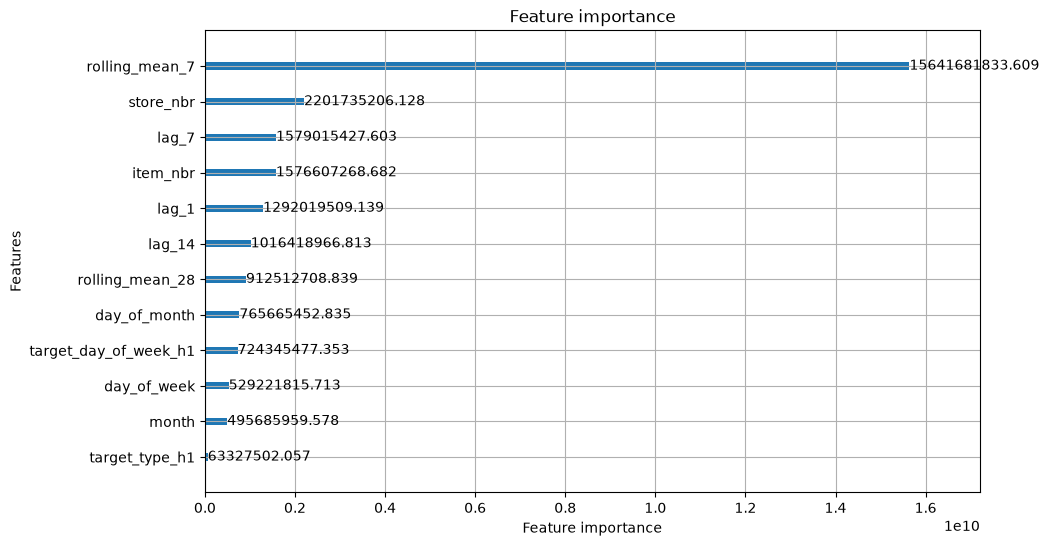

In [69]:
# Смотрим топ-10 самых важных признаков
lgb.plot_importance(model_h1, max_num_features=14, importance_type='gain', figsize=(10, 6))

In [ ]:
df.dtypes

In [ ]:
import pandas as pd
import numpy as np
from datetime import datetime
import lightgbm as lgb
import warnings
warnings.filterwarnings('ignore')

# 1. ЗАГРУЗКА ДАННЫХ
data = pd.read_parquet('../data/train_optimized.parquet')
data_last_year = data[data['date'] >= pd.Timestamp('2016-08-15')].copy()

x_test = pd.read_parquet('../data/output_test_optimized.parquet')

data_oil = pd.read_parquet('../data/output_oil_optimized.parquet')
data_oil = data_oil.sort_values('date')

# Исправлены названия колонок в соответствии с параметрами (21 и 28)
data_oil['dcoilwtico'] = data_oil['dcoilwtico'].ffill().bfill()
data_oil['oil_ma_21'] = data_oil['dcoilwtico'].rolling(window=21, min_periods=1).mean()
data_oil['oil_std_21'] = data_oil['dcoilwtico'].rolling(window=21, min_periods=1).std()
data_oil['oil_lag_28'] = data_oil['dcoilwtico'].shift(28)

data_items = pd.read_parquet('../data/output_items.parquet')
data_items['perishable'] = data_items['perishable'].astype('int8')
data_items['item_weight'] = np.where(data_items['perishable'] == 1, 1.25, 1.0).astype('float32')

# 2. СКЛЕЙКА И БАЗОВАЯ ПОДГОТОВКА
all_data = pd.concat([data_last_year, x_test], ignore_index=True)
all_data['unit_sales'] = all_data['unit_sales'].astype('float32')
all_data = all_data.sort_values(by=['store_nbr', 'item_nbr', 'date'])

# 3. ФИЧИ ИЗ ДАТЫ (Делаем СРАЗУ для всего датасета)
all_data['date'] = pd.to_datetime(all_data['date'])
all_data['year'] = all_data['date'].dt.year.astype('int16')
all_data['month'] = all_data['date'].dt.month.astype('int8')
all_data['day'] = all_data['date'].dt.day.astype('int8')
all_data['day_of_week'] = all_data['date'].dt.dayofweek.astype('int8')

# 4. ЛАГИ И СКОЛЬЗЯЩИЕ СРЕДНИЕ
all_data['lag_16'] = all_data.groupby(['store_nbr', 'item_nbr'])['unit_sales'].shift(16).astype('float32')

# Оптимизированный расчет скользящих окон (работает в разы быстрее, чем lambda)
gb = all_data.groupby(['store_nbr', 'item_nbr'])['lag_16']
all_data['mean_2'] = gb.transform(lambda x: x.rolling(2).mean()).astype('float32') # lambda тут оставлена, если pandas ругается на прямой rolling.transform
all_data['mean_4'] = gb.transform(lambda x: x.rolling(4).mean()).astype('float32')
all_data['mean_6'] = gb.transform(lambda x: x.rolling(6).mean()).astype('float32')
all_data['std_2']  = gb.transform(lambda x: x.rolling(2).std()).astype('float32')
all_data['std_4']  = gb.transform(lambda x: x.rolling(4).std()).astype('float32')
all_data['std_6']  = gb.transform(lambda x: x.rolling(6).std()).astype('float32')

all_data['lag_21'] = all_data.groupby(['store_nbr', 'item_nbr'])['unit_sales'].shift(21).astype('float32')
all_data['lag_28'] = all_data.groupby(['store_nbr', 'item_nbr'])['unit_sales'].shift(28).astype('float32')

# 5. МЕРДЖИ
all_data = all_data.merge(data_oil, on='date', how='left')
all_data = all_data.merge(data_items, on='item_nbr', how='left')

# Обработка промо (тоже для всей таблицы сразу)
all_data['onpromotion'] = all_data['onpromotion'].map({True: 1, False: 0}).fillna(-1).astype('int8')

# Категориальные признаки
cat_cols = ['item_nbr', 'family', 'class', 'store_nbr']
for col in cat_cols:
    if col in all_data.columns:
        all_data[col] = all_data[col].astype('category')

# 6. СПЛИТ НА TRAIN И TEST
train_mask = (all_data['date'] < '2017-08-16') & all_data['lag_28'].notna()
test_mask = all_data['date'] >= '2017-08-16'

train_df = all_data[train_mask].copy()
test_df = all_data[test_mask].copy()

# 7. ПОДГОТОВКА X И y
# Логарифмируем таргет, предварительно убрав отрицательные значения продаж
y = np.log1p(train_df['unit_sales'].clip(lower=0)) 

# Удаляем таргет, дату и id (он пустой в трейне)
drop_cols = ['unit_sales', 'date', 'id']
X = train_df.drop(columns=drop_cols)

# Подготавливаем тестовую выборку (точно те же колонки удаляем)
X_test = test_df.drop(columns=drop_cols)
test_ids = test_df['id'].astype('int32')

# Проверка, что колонки идентичны (полезная практика)
assert list(X.columns) == list(X_test.columns), "Колонки в train и test не совпадают!"

# 8. ОБУЧЕНИЕ МОДЕЛИ
model = lgb.LGBMRegressor(
    n_estimators=300,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

# Можно явно указать модели, какие признаки категориальные
model.fit(X, y, categorical_feature=cat_cols)

# 9. ПРЕДСКАЗАНИЕ
# Возвращаем таргет в исходный масштаб экспонентой (т.к. делали log1p)
predictions = np.expm1(model.predict(X_test))

# 10. СОХРАНЕНИЕ
submission = pd.DataFrame({
    'id': test_ids,         
    'unit_sales': predictions    
})
submission['unit_sales'] = submission['unit_sales'].clip(lower=0)
submission.to_csv('../data/submission9.csv', index=False)



In [33]:
X_test.head()

,store_nbr,item_nbr,onpromotion,year,month,day,day_of_week,lag_16,mean_2,mean_4,...,lag_21,lag_28,dcoilwtico,oil_ma_21,oil_std_21,oil_lag_28,family,class,perishable,item_weight
25,1,96995,0,2017,8,16,2,1.0,1.0,1.0,...,1.0,NaN,46.80,48.375238,1.279166,44.25,GROCERY I,1093,0,1.0
26,1,96995,0,2017,8,17,3,1.0,1.0,1.0,...,1.0,NaN,47.07,48.373810,1.280677,44.40,GROCERY I,1093,0,1.0
27,1,96995,0,2017,8,18,4,1.0,1.0,1.0,...,1.0,NaN,48.59,48.462381,1.224389,45.06,GROCERY I,1093,0,1.0
28,1,96995,0,2017,8,19,5,1.0,1.0,1.0,...,1.0,2.0,NaN,NaN,NaN,NaN,GROCERY I,1093,0,1.0
29,1,96995,0,2017,8,20,6,1.0,1.0,1.0,...,1.0,1.0,NaN,NaN,NaN,NaN,GROCERY I,1093,0,1.0
